## Import Library

In [ ]:
import os
import matplotlib.pyplot as plt
import cv2
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

## Function

### Function Data Understanding

In [ ]:
def switch_to_list(source_folders):
    result = []  

    folders = os.listdir(source_folders)

    for folder in folders:
        folder_images = []  
        
        folder_path = os.path.join(source_folders, folder)
        files = os.listdir(folder_path)
        
        for file in files:
            source_path = os.path.join(folder_path, file)
            img = cv2.imread(source_path)

            folder_images.append(img)

        result.append(folder_images)
    
    return result

In [ ]:
def plot_dataset_distribution(base_path):
    folder_names = sorted(os.listdir(base_path))
    folder_counts = []

    for folder in folder_names:
        folder_path = os.path.join(base_path, folder)
        if os.path.isdir(folder_path):
            num_files = len([file for file in os.listdir(folder_path) if file.lower().endswith(('.png', '.jpg', '.jpeg'))])
            folder_counts.append(num_files)

    plt.figure(figsize=(12, 6))
    bars = plt.bar(folder_names, folder_counts, color='skyblue')

    for bar in bars:
        height = bar.get_height()
        plt.text(bar.get_x() + bar.get_width() / 2.0, height, f'{height}', ha='center', va='bottom', fontsize=10)

    plt.title('Distribusi Jumlah Gambar per Folder')
    plt.xlabel('Nama Folder')
    plt.ylabel('Jumlah Gambar')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

### Function Preprocessing

In [6]:
def grayscale(img):
     result = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
     return result

In [ ]:
def sharpening(image):
    kernel = kernel = np.array([[-1, -1, -1],
                               [-1, 9, -1],
                               [-1, -1, -1]], dtype=np.float32)
    
    pad_size = kernel.shape[0] // 2
    gambar_input = np.pad(image, pad_size, mode='edge')

    gambar_konvolusi = np.zeros_like(image).astype(np.float32)

    baris, kolom = image.shape

    for i in range(baris):
        for j in range(kolom):

            gambar_konvolusi[i, j] = np.sum(gambar_input[i:i + kernel.shape[0], j:j + kernel.shape[1]] * kernel)

    return gambar_konvolusi

In [10]:
def adjust_brightness(image):
    
    mean_val = np.mean(image)
    
    adjustment = 127 - mean_val
    
    if mean_val <= 127:
        adjusted_image = image + adjustment
    else:
        adjusted_image = image - (mean_val - 127)
    
    adjusted_image = np.clip(adjusted_image, 0, 255).astype(np.uint8)
    
    return adjusted_image

In [11]:
def min_max(img):
    image = np.copy(img)
    image_float = image.astype(np.float32)

    min_val = np.min(image_float)
    max_val = np.max(image_float)

    scaled_image = (image_float - min_val) / (max_val - min_val)

    scaled_image_uint8 = (scaled_image * 255).astype(np.uint8)

    return scaled_image_uint8

In [ ]:
def median_filter(image, y=3, x=3):
    padding_size = y // 2
    padded_arr = np.pad(image, padding_size, mode='edge')
    
    copy_arr = np.zeros_like(image).astype(np.float32)
    
    for i in range(image.shape[0]):
        for j in range(image.shape[1]):
            
            sorted_arr = np.sort((padded_arr[i:i + y, j:j + x] / (y * x)).flatten())
            copy_arr[i, j] = sorted_arr[(len(sorted_arr) - 1) // 2]
    
    return copy_arr

def edge_detection(gambar):

    kernel1 = np.array([[-1, 0, 1],
                    [-2, 0, 2],
                    [-1, 0, 1]])

    kernel2 = np.array([[1, 2, 1],
                    [0, 0, 0],
                    [-1, -2, -1]])

    if(kernel1.shape[0] == 3): gambar_input = np.pad(gambar, 1, mode='edge')
    
    else: gambar_input = np.pad(gambar, ((0, 1), (0, 1)), mode='edge')

    hasil = np.zeros_like(gambar).astype(np.float32)

    baris, kolom = gambar.shape

    for i in range(baris):
        for j in range(kolom):

            konvo_x = np.sum(gambar_input[i:i + kernel1.shape[0], j:j + kernel1.shape[1]] * kernel1)
            konvo_y = np.sum(gambar_input[i:i + kernel2.shape[0], j:j + kernel2.shape[1]] * kernel2)
            
            magnitudo = np.sqrt(np.power(konvo_x, 2) + np.power(konvo_y, 2)).astype(hasil.dtype)
            
            hasil[i, j] = magnitudo

    return hasil

In [ ]:
def preprocess(image_list):
    result = []
    
    for images in image_list:
        sub_result = []
        
        for img in images:
            
            processed_img = grayscale(img)

            processed_img = adjust_brightness(processed_img) #

            processed_img = sharpening(processed_img) #4

            processed_img = median_filter(processed_img)

            processed_img = edge_detection(processed_img) #

            processed_img = min_max(processed_img) #
                
            sub_result.append(processed_img)
        
        result.append(sub_result)
    
    return result

### Function Ekstraksi Fitur

In [ ]:
def calculate_glcm(img, distances, angles):
    max_gray_level = 256
    glcm = np.zeros((max_gray_level, max_gray_level, len(distances), len(angles)), dtype=np.float64)
    rows, cols = img.shape

    for d, distance in enumerate(distances):
        for a, angle in enumerate(angles):
            dx = int(np.round(np.cos(angle) * distance))
            dy = int(np.round(np.sin(angle) * distance))
            
            for i in range(rows):
                for j in range(cols):
                    new_i = i + dy
                    new_j = j + dx
                    if 0 <= new_i < rows and 0 <= new_j < cols:
                        glcm[img[i, j], img[new_i, new_j], d, a] += 1

    glcm /= np.sum(glcm, axis=(0, 1), keepdims=True)
    return glcm

def extract_features(glcm):
    features = {}
    num_levels = glcm.shape[0]
    
    mean_i = np.sum(np.arange(num_levels)[:, None] * glcm, axis=(0, 1))
    mean_j = np.sum(np.arange(num_levels)[None, :] * glcm, axis=(0, 1))
    std_i = np.sqrt(np.sum((np.arange(num_levels)[:, None] - mean_i) ** 2 * glcm, axis=(0, 1)))
    std_j = np.sqrt(np.sum((np.arange(num_levels)[None, :] - mean_j) ** 2 * glcm, axis=(0, 1)))

    features['contrast'] = np.sum((np.arange(num_levels)[:, None] - np.arange(num_levels)[None, :]) ** 2 * glcm, axis=(0, 1))
    features['dissimilarity'] = np.sum(np.abs(np.arange(num_levels)[:, None] - np.arange(num_levels)[None, :]) * glcm, axis=(0, 1))
    features['homogeneity'] = np.sum(glcm / (1.0 + (np.arange(num_levels)[:, None] - np.arange(num_levels)[None, :]) ** 2), axis=(0, 1))
    features['energy'] = np.sqrt(np.sum(glcm ** 2, axis=(0, 1)))
    features['correlation'] = np.sum((np.arange(num_levels)[:, None] * np.arange(num_levels)[None, :] * glcm - mean_i * mean_j) / (std_i * std_j), axis=(0, 1))
    features['entropy'] = -np.sum(glcm * np.log2(glcm + (glcm == 0)), axis=(0, 1))
    features['asm'] = np.sum(glcm ** 2, axis=(0, 1))

    return features

def extract_features_glcm(grayscale_images, distances=[1, 2, 3, 4, 5], labels=['a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i', 'k', 'l', 'm', 'n', 'o', 'p', 'q', 'r', 's', 't', 'u', 'v', 'w', 'x', 'y']
):
    angles = [0, np.pi / 4, np.pi / 2, 3 * np.pi / 4]  # 0, 45, 90, dan 135 derajat dalam satuan radian
    features_list = []

    for folder_index, folder_images in enumerate(grayscale_images):
        for img in folder_images:
            # img_features = []
            glcm = calculate_glcm(img, distances, angles)
            
            
            for d in range(len(distances)):
                features_at_angle = {}
                
                for a in range(len(angles)):
                    features = extract_features(glcm[:, :, d, a])
                    for key, value in features.items():
                        features_at_angle[f'{key}_{int(np.degrees(angles[a]))}'] = value
                features_at_angle['label'] = labels[folder_index]
                features_list.append(features_at_angle)
    
    return features_list

## Data Understanding

In [16]:
the_folders = 'asl'

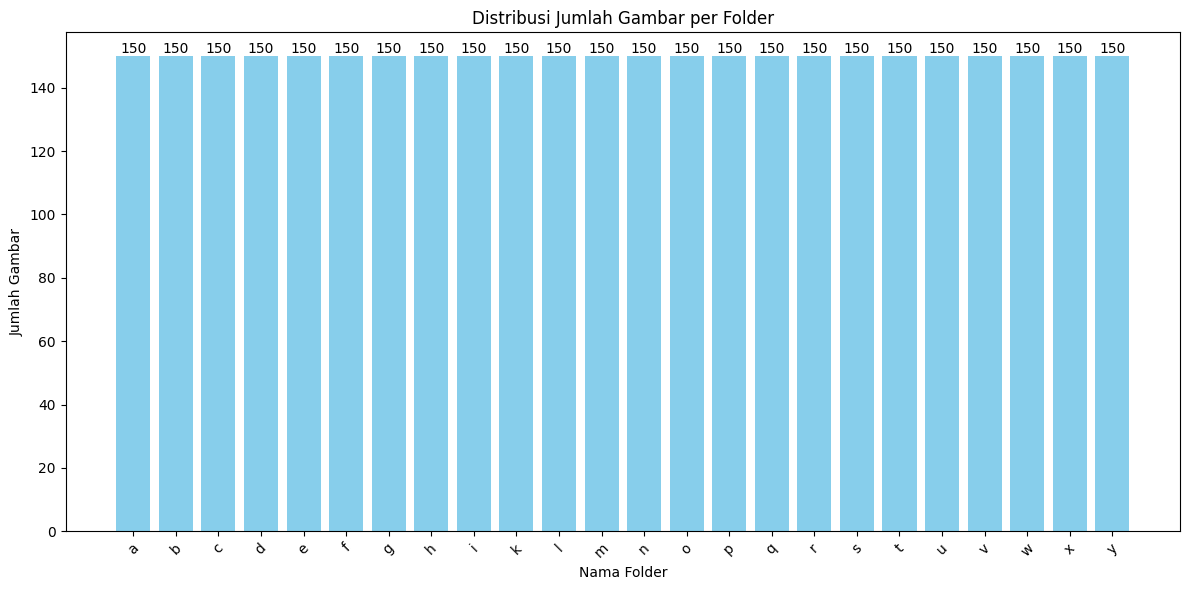

In [17]:
plot_dataset_distribution(the_folders)

In [18]:
the_list = switch_to_list(the_folders)

In [19]:
# print_each_list(the_list, 2)

## Preprocessing

In [20]:
preprocessed_list = preprocess(the_list)

In [21]:
# print_each_list(preprocessed_list, 2, "gray")

## Extraction Feature

In [22]:
glcm_features = extract_features_glcm(preprocessed_list)

In [23]:
features_df = pd.DataFrame(glcm_features)

In [24]:
features_df.head(10)

,contrast_0,dissimilarity_0,homogeneity_0,energy_0,correlation_0,entropy_0,asm_0,contrast_45,dissimilarity_45,homogeneity_45,...,entropy_90,asm_90,contrast_135,dissimilarity_135,homogeneity_135,energy_135,correlation_135,entropy_135,asm_135,label
0,553.141212,10.051313,0.465174,0.330449,-18258.516756,7.650687,0.109197,818.486175,12.355780,0.440976,...,7.448445,0.115163,715.869707,11.720131,0.441679,0.322719,-18356.133217,7.745588,0.104147,a
1,1074.710204,15.423469,0.413684,0.311750,-18497.657779,7.963842,0.097188,818.486175,12.355780,0.440976,...,7.733509,0.106525,715.869707,11.720131,0.441679,0.322719,-18356.133217,7.745588,0.104147,a
2,1306.763299,17.690515,0.391361,0.294304,-18743.002091,8.198272,0.086615,1383.744065,17.820491,0.400291,...,7.870514,0.101948,1198.426281,16.469596,0.402031,0.301279,-18826.111618,8.067827,0.090769,a
3,1585.434375,20.015208,0.368839,0.280697,-18991.053936,8.394746,0.078791,1714.954405,20.452758,0.368350,...,7.969960,0.098370,1495.231799,19.078542,0.375157,0.281180,-19099.576827,8.304674,0.079062,a
4,1739.891368,21.466947,0.350994,0.266540,-19244.663092,8.544967,0.071044,1882.667535,22.028429,0.346145,...,8.063540,0.095211,1665.724826,20.734592,0.351365,0.265691,-19435.060684,8.492732,0.070592,a
5,575.075556,10.308687,0.470324,0.338507,-17984.820096,7.593953,0.114587,848.816549,12.410672,0.446907,...,7.408950,0.122196,787.002653,12.184573,0.448608,0.332643,-18108.231370,7.725350,0.110652,a
6,1150.918571,15.884490,0.422690,0.320513,-18219.608137,7.926345,0.102728,848.816549,12.410672,0.446907,...,7.675665,0.114548,787.002653,12.184573,0.448608,0.332643,-18108.231370,7.725350,0.110652,a
7,1409.362680,18.341031,0.394505,0.305252,-18460.460159,8.145333,0.093178,1452.345689,17.982091,0.408160,...,7.794860,0.110295,1298.160558,16.940858,0.410297,0.313987,-18565.971269,8.010628,0.098588,a
8,1708.723854,20.638854,0.376010,0.290037,-18707.374680,8.352082,0.084121,1751.300457,20.494845,0.382364,...,7.890412,0.107624,1610.449782,19.598470,0.384948,0.296292,-18893.140253,8.237860,0.087789,a
9,1875.318842,22.079053,0.357742,0.275879,-18959.711543,8.510143,0.076109,1944.776584,22.311089,0.358146,...,7.976427,0.104766,1808.691298,21.399414,0.364955,0.279746,-19234.993610,8.446628,0.078258,a


In [ ]:
# features_df.to_csv('ekstraksi_fitur.csv', index=False)

In [ ]:
# features_df = pd.read_csv('ekstraksi_fitur.csv')

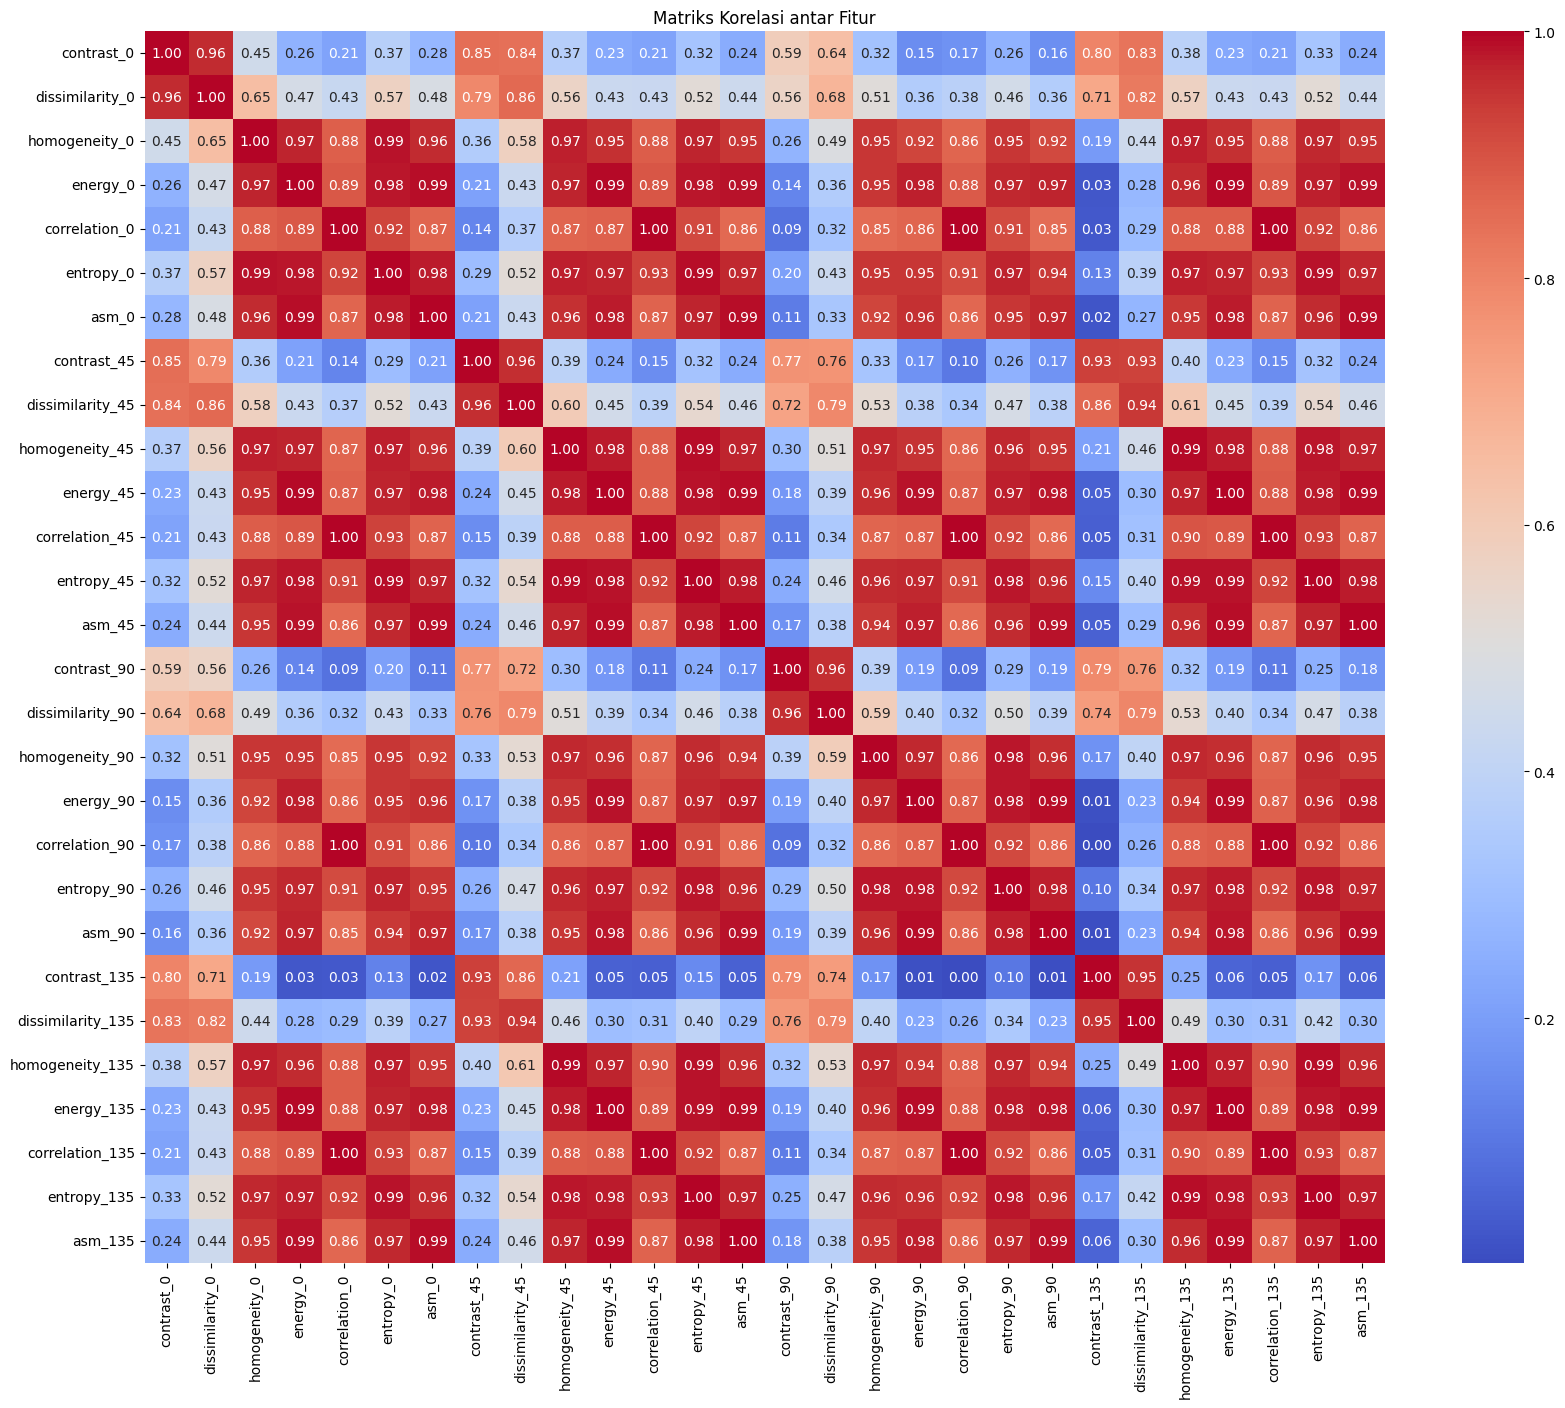

In [27]:
correlation_matrix = features_df.drop('label', axis=1).corr().abs()

plt.figure(figsize=(20, 16))

sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")

plt.title('Matriks Korelasi antar Fitur')

plt.show()

## Feature Selection

In [28]:
features_to_drop = set()

for i in range(len(correlation_matrix.columns)):
    for j in range(i+1, len(correlation_matrix.columns)):
        if correlation_matrix.iloc[i, j] > 0.9:
            col1 = correlation_matrix.columns[i]
            col2 = correlation_matrix.columns[j]

            features_to_drop.add(col2)

filtered_features_df = features_df.drop(columns=list(features_to_drop))

In [ ]:
# filtered_features_df.to_csv('filtered_ekstraksi_fitur.csv', index=False)

In [ ]:
# filtered_features_df = pd.read_csv('filtered_ekstraksi_fitur_sebelum.csv')

In [31]:
# filtered_features_df = features_df[['contrast_0', 'homogeneity_0', 'energy_0', 'correlation_0', 'entropy_0', 'label']]

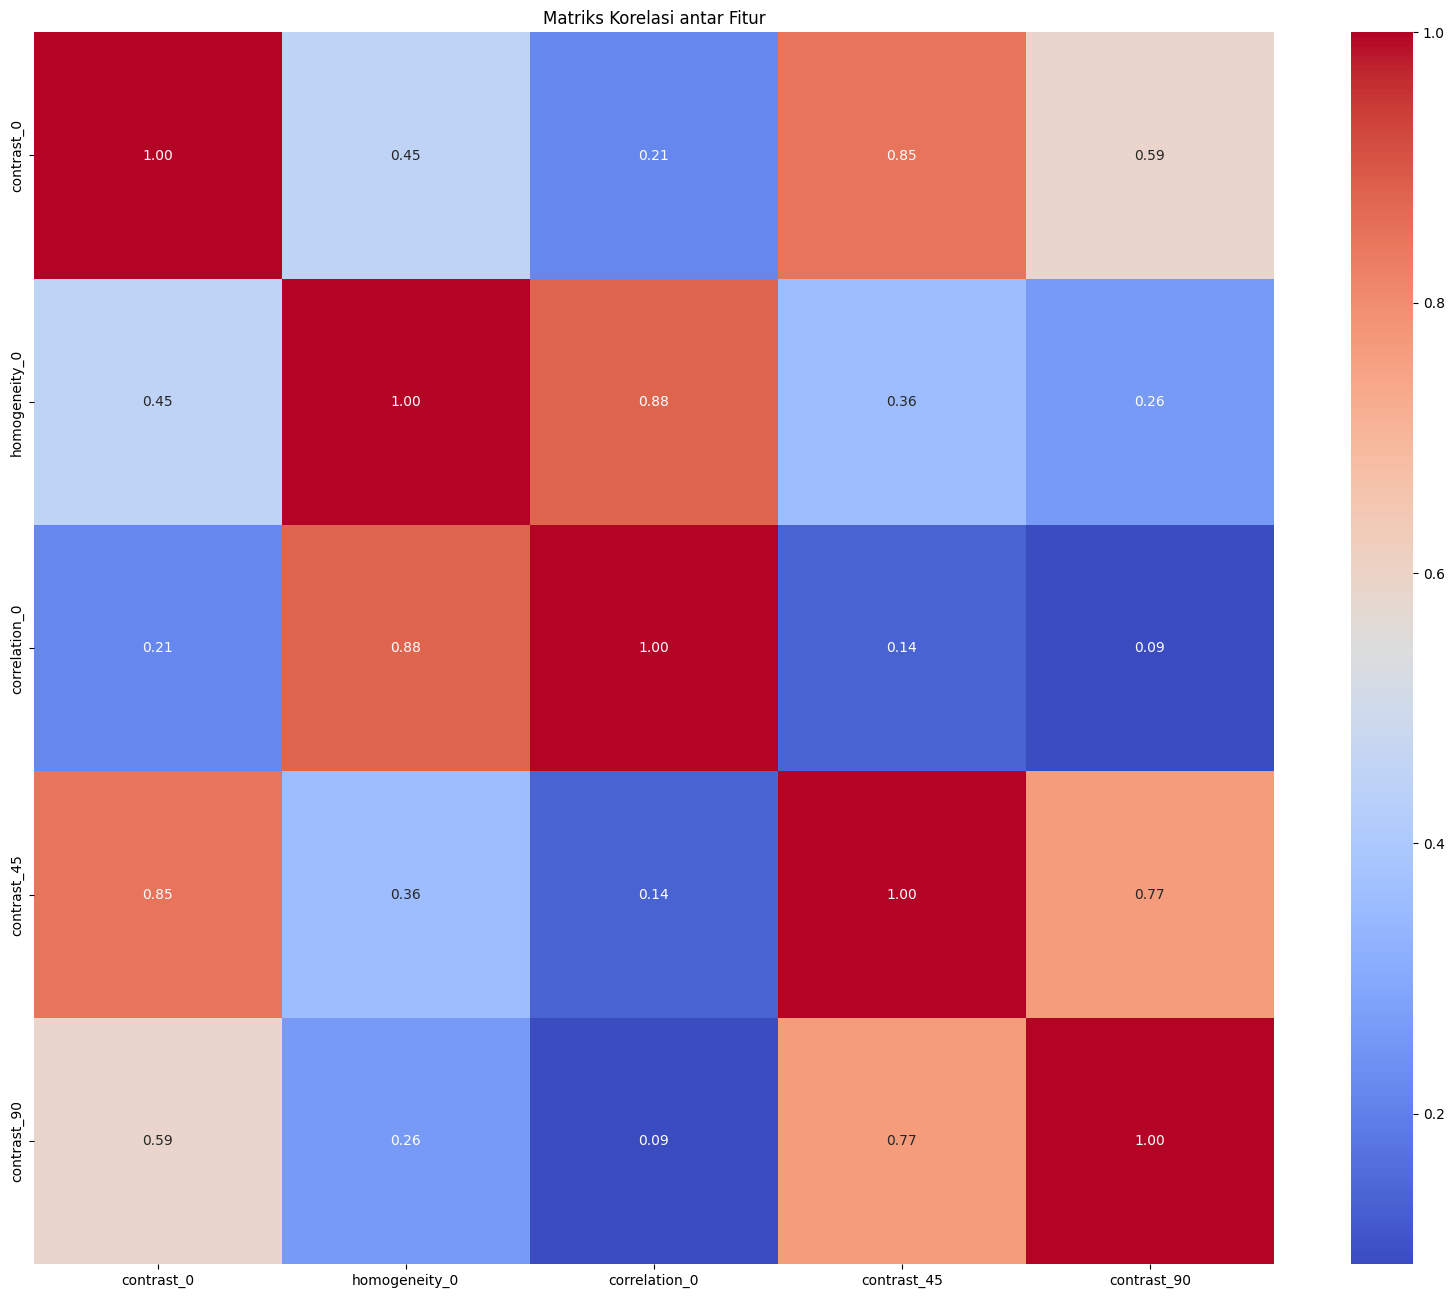

In [32]:
correlation_matrix_2 = filtered_features_df.drop('label', axis=1).corr().abs()

plt.figure(figsize=(20, 16))

sns.heatmap(correlation_matrix_2, annot=True, cmap='coolwarm', fmt=".2f")

plt.title('Matriks Korelasi antar Fitur')

plt.show()

## Splitting Data 

In [ ]:
XX = filtered_features_df.drop(columns=['label']).values
yy = filtered_features_df['label'].values

X_train, X_test, y_train, y_test = train_test_split(XX, yy, test_size=0.20, random_state=42)

## Normalization

In [34]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

## Modeling

In [35]:
hasil_model = {
    'KNN': {'accuracy': [], 'precision': [], 'recall': [], 'f1_score': []},
    'SVM': {'accuracy': [], 'precision': [], 'recall': [], 'f1_score': []},
    'Random Forest': {'accuracy': [], 'precision': [], 'recall': [], 'f1_score': []}
}

In [36]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)
y_pred_knn = knn.predict(X_test)
report_knn = classification_report(y_test, y_pred_knn, output_dict=True, zero_division=0)
hasil_model['KNN']['accuracy'].append(report_knn['accuracy'])
hasil_model['KNN']['precision'].append(report_knn['weighted avg']['precision'])
hasil_model['KNN']['recall'].append(report_knn['weighted avg']['recall'])
hasil_model['KNN']['f1_score'].append(report_knn['weighted avg']['f1-score'])

svm = SVC(kernel='rbf', random_state=42)
svm.fit(X_train, y_train)
y_pred_svm = svm.predict(X_test)
report_svm = classification_report(y_test, y_pred_svm, output_dict=True, zero_division=0)
hasil_model['SVM']['accuracy'].append(report_svm['accuracy'])
hasil_model['SVM']['precision'].append(report_svm['weighted avg']['precision'])
hasil_model['SVM']['recall'].append(report_svm['weighted avg']['recall'])
hasil_model['SVM']['f1_score'].append(report_svm['weighted avg']['f1-score'])

rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)
report_rf = classification_report(y_test, y_pred_rf, output_dict=True, zero_division=0)
hasil_model['Random Forest']['accuracy'].append(report_rf['accuracy'])
hasil_model['Random Forest']['precision'].append(report_rf['weighted avg']['precision'])
hasil_model['Random Forest']['recall'].append(report_rf['weighted avg']['recall'])
hasil_model['Random Forest']['f1_score'].append(report_rf['weighted avg']['f1-score'])

df_hasil = pd.DataFrame(hasil_model).T
print(df_hasil)


                           accuracy             precision  \
KNN            [0.7541666666666667]  [0.7601583509507475]   
SVM                        [0.5775]  [0.5733124063949953]   
Random Forest  [0.8502777777777778]  [0.8519074094616332]   

                             recall              f1_score  
KNN            [0.7541666666666667]  [0.7555060950226187]  
SVM                        [0.5775]  [0.5687864957390484]  
Random Forest  [0.8502777777777778]  [0.8501916768345595]  


## Evaluation

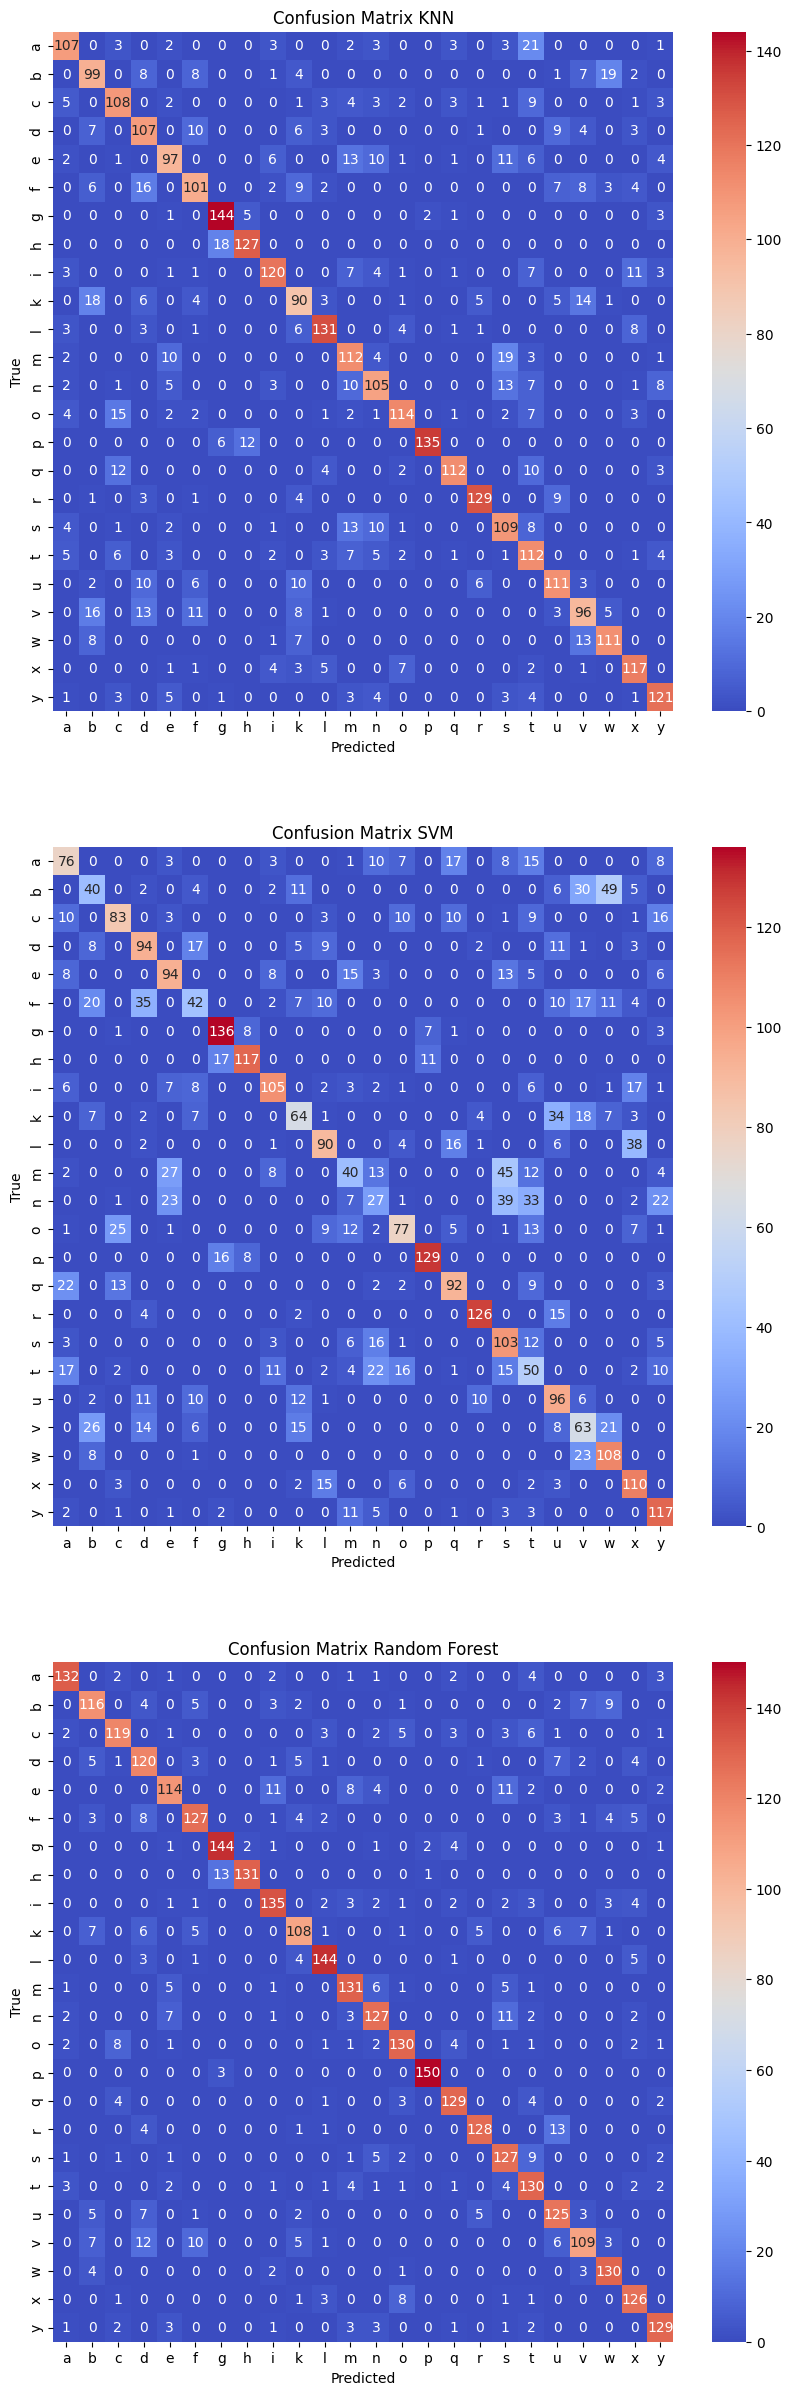

In [37]:
cm_knn = confusion_matrix(y_test, y_pred_knn)
cm_svm = confusion_matrix(y_test, y_pred_svm)
cm_rf = confusion_matrix(y_test, y_pred_rf)

labels = ['a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i', 'k', 'l', 'm', 'n', 'o', 'p', 'q', 'r', 's', 't', 'u', 'v', 'w', 'x', 'y']

num_classes = len(np.unique(y_test))
labels = labels[:num_classes]

fig, axes = plt.subplots(3, 1, figsize=(10, 30))

sns.heatmap(cm_knn, annot=True, cmap='coolwarm', fmt='g', ax=axes[0], xticklabels=labels, yticklabels=labels)
axes[0].set_title('Confusion Matrix KNN')
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("True")

sns.heatmap(cm_svm, annot=True, cmap='coolwarm', fmt='g', ax=axes[1], xticklabels=labels, yticklabels=labels)
axes[1].set_title('Confusion Matrix SVM')
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("True")

sns.heatmap(cm_rf, annot=True, cmap='coolwarm', fmt='g', ax=axes[2], xticklabels=labels, yticklabels=labels)
axes[2].set_title('Confusion Matrix Random Forest')
axes[2].set_xlabel("Predicted")
axes[2].set_ylabel("True")

plt.show()